# Logistic Regression Model
For a logistic regression model we must have our data sufficiently preprocessed in order for our model to make accurate predictions. The preprocessing steps we utilize for our model include omitting duplicates, imputing null values, dealing with outliers, scaling features, and checking collinearity. We have already dealt with duplicates, partitioning, removing collinear features, and imputation, so now we must deal with outliers and scaling. Recall we are dealing with highly skewed finacial data where outliers can be signs of great changes in companies finances making them very important for predicting bankruptcy. We choose to use the "Robust Scaling" method to account for our outliers and also scale our features at the same time. The robust scaling formula is described below:
$$
\tilde{x} = \frac{x - \text{median}(x)}{\text{IQR}(x)}
$$
When using standardization (z-score transformation) as a scaler we take the difference between our observation and the mean of the feature, and divide it by the features standard deviation. This only alters the scale of our distribution while also preserving the long-tails from our skewness, so this is not viable for our dataset. Standardizing also is extremely sensitive to outliers as we are computing new data from a heavily distorted mean and standard deviation. Now the issue with capping our outliers (winsorization) would be that we are limiting the scope of our possible predictions. What if a company has a large negative cash-to-assets ratio? This would definitely be a marker for imminent bankrupty, but winsorizing this feature would would mean we drop this datum. The robust scaler would fix both issues of needing to preserve our outliers while also handling the scaling neccessary for our logistic regression model.

## Importing Libraries:

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import RobustScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report , roc_auc_score, average_precision_score

## Loading our Preprocessed Data:

In [2]:
X_train = pd.read_csv("X_train_lr.csv")
X_test = pd.read_csv("X_test_lr.csv")

y_train = pd.read_csv("y_train.csv")["class"]
y_test = pd.read_csv("y_test.csv")["class"]

## Modeling:
Recall a logistic regression model functions by computing continous probabilities of a binary outcome (e.g. companies filing for bankruptcy or not). It does this by mapping our input features into a probabilitiy using a linear combination and the sigmoid function.
$$z=w_{1}x_{1}+w_{2}x_{2}+\dots +w_{n}x_{n}+b$$

$$\hat{y}=\sigma (z)=\frac{1}{1+e^{-z}}$$ 
Where:
- $w$ represents the weights (coefficients).
- $x$ represents the input features (finacial ratios).
- $b$ represents the bias term.
- $\hat{y}$ is the predicted probability that the true label $y$ is 1 (Bankrupt).




To derive the optimal weights for each feature, the model iteratively minimizes the log-loss function. Here is the standard formula for a dataset with $n$ samples:

$$\text{Log-Loss}=-\frac{1}{n}\sum _{i=1}^{n}\left[y_{i}\log (\hat{{y}_{i}})+(1-y_{i})\log (1-{\hat{y}_{i}})\right]$$

Where $y_i$ represents the true binary label and $\hat{y}_i$ represents the model's predicted probability. For example, say we have three companies that actually file for bankruptcy i.e. $y = 1$, and our model predicted a probability of $\hat{y} = 0.98$ or 98%, a confident prediction. Then our log-loss function equals $-\log(0.98) = 0.020 $ almost zero. So our log-loss function would hardly penalize our model for making such a confident but correct prediction.

Say our model makes a prediction for another company that files for bankruptcy with a probability of $\hat{y_i}=0.45$. This probability signifies that our model is unsure whether this company will file for bankruptcy, but overall it points towards predicting this company won't go bankrupt. The log-loss function would calculate $-\log(0.45) = 0.798$. So our model is somewhat penalized for this incorrect predictions.

Lastly what if we have another company that went bankrupt, but our model would predict a 1% chance of going bankrupt, $\hat{y_i}=0.01$, another confident prediction but this time we say that a company will definitely not go bankrupt. Our log-loss model would equal $-\log(0.01) = 4.605$ a heavy penalty.

The optimization algorithm (Gradient Descent) works by continuously minimizing this function until the difference between iterations becomes negligible, yielding the most optimized feature weights.

Now because financial data sets are normally interconnected, training a baseline logistic regression model could possibly introduce multicollinearity and some overfitting. This also could be attributed to the severe class imbalance present in many fraud/bankruptcy classification datasets. To mitigate this, we can introduce the "L1-Regularization Penalty" into our logistic regression model. This penalty introduces a structural constraint that controls the magnitude of our feature weights. It modifies our baseline cost function by appending the absolute sum of all model coefficients directly to the log-loss equation. Mathematically, the new objective function looks like this:

$$\text{Total\ Cost}=\text{Log-Loss}+\lambda \sum _{j=1}^{m}\left|w_{j}\right|$$

Where $w_{j}$ represents the individual weight assigned to feature $j$, and $\lambda$ (lambda) acts as a tuning knob that dictates the exact severity of the penalty.

To see how this works in practice, let’s revisit our bankruptcy dataset. Suppose we throw 50 different financial ratios into our model—such as the current ratio, debt-to-equity ratio, and net profit margin. Because financial metrics are deeply interconnected, many of these ratios will move together, creating redundant noise.

Without a penalty, our baseline model tries too hard to fit every single metric. It might give a weight of $+2.5$ to one liquidity ratio and $-2.1$ to another highly correlated one just to shave a tiny fraction off the log-loss. Recall these are weights that our model derives on it's own, where the positive value would mean the higher the feature or financial ratio goes the model would strongly shift its prediction to 1. While the negative weight would signify the higher the feature goes, the more likely the model would predict 0. 

Because these two financial ratios are highly correlated, they move together like twins. If a company is in financial distress, both metrics will spike or drop at the exact same time. When your model is unregularized, it only cares about minimizing the final log-loss by any means necessary. If offsetting these two twin metrics by massive, opposing numbers $+2.5$ and $-2.1$ helps it perfectly predict just one extra tricky company in your training data, it will do it. The two weights essentially engage in a game of tug-of-war, cancel each other out for most companies, but create an unstable, overfitted rule just to shave a microscopic fraction off the final training log-loss.

When you turn on the L1 penalty, the model is forced to look at the absolute physical cost of those massive weights:
$$\text{Penalty\ Cost}=\lambda (|2.5|+|-2.1|)=\lambda (4.6)$$

Suddenly, keeping both features carries a massive penalty price tag of $4.6$. Because the two metrics tell the exact same financial story, keeping both of them doesn't actually help the model learn anything new. The optimization algorithm realizes it can get the exact same predictive power by simply dropping one feature entirely (setting its weight to $0$) and giving the other a modest, stable weight (like $+0.4$).

When we introduce the L1 penalty, the model can no longer assign weights freely. Every single non-zero weight adds a direct dollar-amount penalty to our total cost. The optimization algorithm must now play a game of economic trade-offs: Does keeping this feature reduce the log-loss enough to justify the penalty cost of its weight?

For instance, say the model is evaluating a highly specific, redundant ratio. Keeping it in the model only reduces our log-loss by a microscopic $0.001$, but adding its absolute weight to the penalty increases the total cost by $0.150$. Since the penalty cost outweighs the log-loss benefit, the optimization algorithm chooses the ultimate cost-saving measure. So it slashes that feature’s weight down to exactly zero. By driving unimportant or redundant feature weights to absolute zero, the L1 penalty automatically performs feature selection. Instead of forcing an analyst to manually guess which financial ratios to drop, the model mathematically strips away the noise, leaving you with a clean, sparse set of the most critical predictors for bankruptcy.

In [3]:
# 1. Model A: Standard Logistic Regression
standard_pipeline = Pipeline([('scaler', RobustScaler()),
                              ('model', LogisticRegression(penalty=None,
                                                           solver = 'saga',
                                                           class_weight='balanced',
                                                           random_state=2004,
                                                           max_iter=5000))])

print("Training Model A (Standard)...")
standard_pipeline.fit(X_train, y_train)
y_pred_std = standard_pipeline.predict(X_test)
y_proba_std = standard_pipeline.predict_proba(X_test)[:, 1]


# 2. Model B: Logistic Regression with L1 Penalty
l1_pipeline = Pipeline([('scaler', RobustScaler()),
                        ('model', LogisticRegression(penalty='l1',
                                                     solver='liblinear',
                                                     C = 0.1,
                                                     class_weight = 'balanced',
                                                     random_state=2004,
                                                     max_iter=5000))])

print("Training Model B (L1-Penalty)...")
l1_pipeline.fit(X_train, y_train)
y_pred_l1 = l1_pipeline.predict(X_test)
y_proba_l1 = l1_pipeline.predict_proba(X_test)[:, 1]


# 3. SIDE-BY-SIDE PERFORMANCE EVALUATION
print("="*50)
print("MODEL 1: STANDARD LOGISTIC REGRESSION")
print("="*50)
print(classification_report(y_test, y_pred_std))
print(f"Test AUC-ROC Score: {roc_auc_score(y_test, y_proba_std):.4f}\n")
print(f"Test PR-AUC Score:  {average_precision_score(y_test, y_proba_std):.4f}\n")

print("="*50)
print("MODEL 2: LOGISTIC REGRESSION (L1 PENALTY)")
print("="*50)
print(classification_report(y_test, y_pred_l1))
print(f"Test AUC-ROC Score: {roc_auc_score(y_test, y_proba_l1):.4f}\n")
print(f"Test PR-AUC Score:  {average_precision_score(y_test, y_proba_l1):.4f}\n")
print("-"*50)

coef_l1 = l1_pipeline.named_steps['model'].coef_[0]
kept_features = sum(coef_l1 != 0)
dropped_features = sum(coef_l1 == 0)


print(f"L1 Regularization Structural Summary:")
print(f" - Out of the {len(coef_l1)} preprocessed features passed in:")
print(f"   - L1 Kept: {kept_features} features active")
print(f"   - L1 Dropped: {dropped_features} features (coefficients driven to exactly 0)")

Training Model A (Standard)...


/Users/dan/tf_project_env/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


Training Model B (L1-Penalty)...
MODEL 1: STANDARD LOGISTIC REGRESSION
              precision    recall  f1-score   support

           0       0.97      0.60      0.74      1985
           1       0.07      0.59      0.12        99

    accuracy                           0.60      2084
   macro avg       0.52      0.59      0.43      2084
weighted avg       0.92      0.60      0.71      2084

Test AUC-ROC Score: 0.6100

Test PR-AUC Score:  0.0784

MODEL 2: LOGISTIC REGRESSION (L1 PENALTY)
              precision    recall  f1-score   support

           0       0.97      0.88      0.92      1985
           1       0.18      0.55      0.27        99

    accuracy                           0.86      2084
   macro avg       0.58      0.71      0.60      2084
weighted avg       0.94      0.86      0.89      2084

Test AUC-ROC Score: 0.7739

Test PR-AUC Score:  0.1944

--------------------------------------------------
L1 Regularization Structural Summary:
 - Out of the 45 preprocessed fe

In [6]:
y_prob_l1 = l1_pipeline.predict_proba(X_test)[:,1]

thresholds = [0.1, 0.2, 0.3, 0.4, 0.5]
print("Threshold | Recall (Class 1) | Precision (Class 1)")
print("-" * 47)

for t in thresholds:
    preds = (y_prob_l1 >= t).astype(int)
    report = classification_report(y_test, preds, output_dict=True)
    rec = report['1']['recall']
    prec = report['1']['precision']
    print(f"  {t:.2f}    |      {rec:.2f}       |        {prec:.2f}")

Threshold | Recall (Class 1) | Precision (Class 1)
-----------------------------------------------
  0.10    |      0.98       |        0.05
  0.20    |      0.95       |        0.05
  0.30    |      0.86       |        0.07
  0.40    |      0.61       |        0.13
  0.50    |      0.55       |        0.18


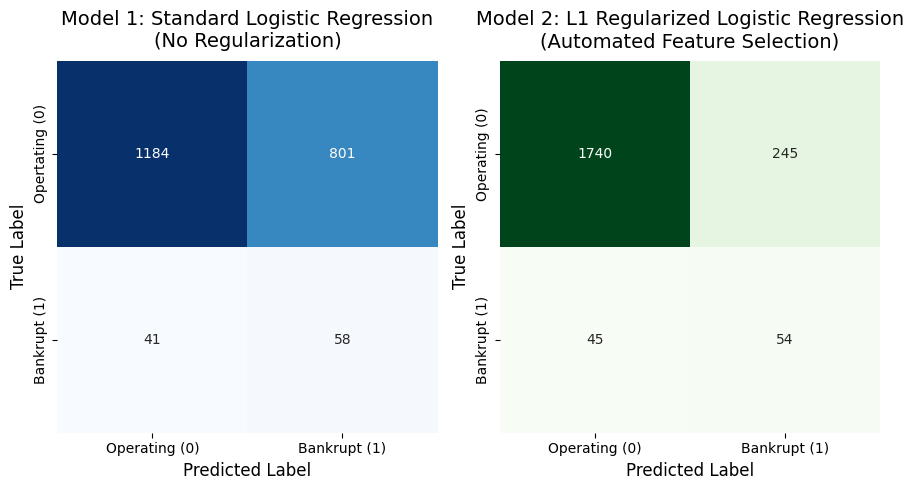

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm_std = confusion_matrix(y_test, y_pred_std)
cm_l1 = confusion_matrix(y_test, y_pred_l1)

fig, axes = plt.subplots(1, 2, figsize=(9,5))

sns.heatmap(cm_std, annot=True, fmt='d', cmap='Blues', ax=axes[0], cbar=False,
            xticklabels=['Operating (0)', 'Bankrupt (1)'], 
            yticklabels=['Opertating (0)', 'Bankrupt (1)'])
axes[0].set_title('Model 1: Standard Logistic Regression\n(No Regularization)', fontsize=14, pad=10)
axes[0].set_xlabel('Predicted Label', fontsize=12)
axes[0].set_ylabel('True Label', fontsize=12)

sns.heatmap(cm_l1, annot=True, fmt='d', cmap='Greens', ax=axes[1], cbar=False,
            xticklabels=['Operating (0)', 'Bankrupt (1)'], 
            yticklabels=['Operating (0)', 'Bankrupt (1)'])
axes[1].set_title('Model 2: L1 Regularized Logistic Regression\n(Automated Feature Selection)', fontsize=14, pad=10)
axes[1].set_xlabel('Predicted Label', fontsize=12)
axes[1].set_ylabel('True Label', fontsize=12)

plt.tight_layout()
plt.show()

In [15]:
feature_names = X_train.columns if hasattr(X_train, 'columns') else [f"Feature {i}" for i in range(X_train.shape[1])]

coef_l1 = l1_pipeline.named_steps['model'].coef_[0]

l1_features_df = pd.DataFrame({
    'Feature Name': feature_names,
    'L1 Coefficient': coef_l1
})

dropped_features_df = l1_features_df[l1_features_df['L1 Coefficient'] == 0].reset_index(drop=True)

print(f"=== FEATURES DROPPED BY L1 REGULARIZATION ({len(dropped_features_df)} TOTAL) ===")
print("-" * 65)
for idx, row in dropped_features_df.iterrows():
    print(f" X {row['Feature Name']}")

=== FEATURES DROPPED BY L1 REGULARIZATION (11 TOTAL) ===
-----------------------------------------------------------------
 X Attr2
 X Attr36
 X missingindicator_Attr4
 X missingindicator_Attr5
 X missingindicator_Attr9
 X missingindicator_Attr13
 X missingindicator_Attr15
 X missingindicator_Attr32
 X missingindicator_Attr37
 X missingindicator_Attr45
 X missingindicator_Attr61


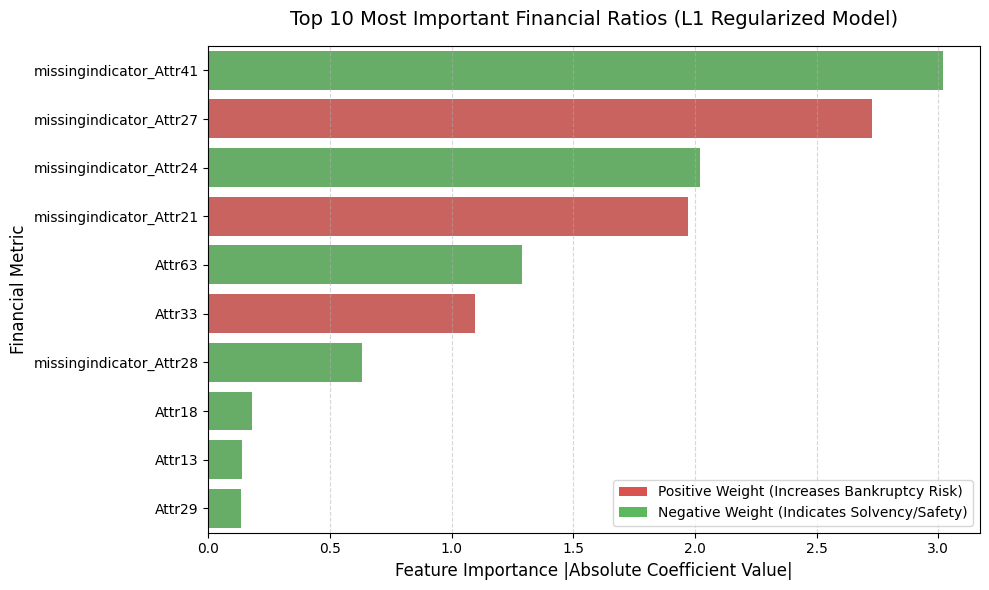

In [5]:
feature_names = X_train.columns if hasattr(X_train, 'columns') else [f"Feature {i}" for i in range(X_train.shape[1])]
coef_values = l1_pipeline.named_steps['model'].coef_[0]

feature_importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': coef_values,
    'Absolute_Magnitude': np.abs(coef_values)
})

important_features = feature_importance_df[feature_importance_df['Coefficient'] != 0]
top_10_features = important_features.sort_values(by='Absolute_Magnitude', ascending=False).head(10)

plt.figure(figsize=(10, 6))
colors = ['#d9534f' if c > 0 else '#5cb85c' for c in top_10_features['Coefficient']]

sns.barplot(
    x='Absolute_Magnitude', 
    y='Feature', 
    data=top_10_features, 
    palette=colors,
    hue='Feature',
    legend=False
)

plt.title('Top 10 Most Important Financial Ratios (L1 Regularized Model)', fontsize=14, pad=15)
plt.xlabel('Feature Importance |Absolute Coefficient Value|', fontsize=12)
plt.ylabel('Financial Metric', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.5)

from matplotlib.patches import Patch
legend_elements = [Patch(facecolor='#d9534f', label='Positive Weight (Increases Bankruptcy Risk)'),
                   Patch(facecolor='#5cb85c', label='Negative Weight (Indicates Solvency/Safety)')]
plt.legend(handles=legend_elements, loc='lower right')

plt.tight_layout()
plt.show()

## Results:
In finance specifically when dealing with bankruptcy detection, a False Negative (predicting a company is safe when it actually goes bankrupt) is vastly more expensive than a False Positive (predicting bankruptcy for a healthy company). If a bank or investor misses a bankruptcy (FN), they face catastrophic asset write-offs and lose their entire principal investment; if they raise a false alarm (FP), they merely incur the administrative cost of a stricter credit audit or miss out on a marginal interest payment. So we will focus our attention on confusion matrices, recall, and PR-AUC to determine the best models.

Now that we finished all of the modeling we must take a look at each models classification report and confusion matrix. Recall our data suffers from severe class imbalance so we cannot simply rely on the "accuracy" metric to rate the prediction power. We must account for the "recall","precision", and "F1-score" to make any meaningful inference from our models predictions. Specifically a high recall would mean we have a low rate of false negatives which is what we are focusing on.

Now when training our baseline logistic model, we would encounter the problem where our machine ran through the maximum amount of iterations before converging on the minimized log-loss value. Looking at our ROC-AUC score we reached a miserable 61.00% and a PR-AUC score of 7.84%, meaning that the models prediction power is slightly better than flipping a coin and that its barely able to predict the positive class (bankruptcy). We even have a measly 59% recall and 7% precision for predicting bankruptcy, meaning out 99 companies truly labeled bankruptcy 58 of them were correct; and out of 828 companies predicted to go bankrupt only 58 of them actually went under. This makes our model prone to a bunch of false-positives, which our confusion matrix would agree with. Our F1-score would also hardly reach 12%. To summarize the baseline logistic regression model would perform poorly in predicting bankruptcy.

The logistic regression model most likely failed due to the hidden interconnectedness of our financial data. For example there might have been more than one feature that our log-loss function wouldn't be able to find the optimum weights because they are multicollinear. Recall we have already dropped the highest collinear features in our data, and have set the weights of our model to "balanced" to account for the severe class imbalance. It goes to show that our baseline logistic regression model with balanced weights lacks the mathematical rigour to efficiently predict labels in this complicated dataset. This is why we introduce the robust "L1-Regularization Penalty" in order to improve our predictions.

We previously discussed how the L1 penalty works, so we will go straight into discussing the metrics of our predictions on our testing data. This time we would encounter no issue in training, and would actually achieve a well-rounded ROC-AUC score of 77.39% and a PR-AUC score of 19.44%. Not only is our model better at differentiating our class labels it also has a higher chance of prediciting our positive class. Our recall and precision scores would increase to 55% and 18% respectively; meaning out of 99 companies truly labeled bankruptcy 54 of them were correct, and that out of 300 companies predicted to go bankrupt only 54 of them did. Our scale of false-positives is significantly lowered from the previous 828 companies predicted to go bankrupt in our baseline linear regression model. The confusion matrix would reinforce our conclussion by displaying the 245 false-positives and 45 false-negatives. Our F1-score would also increase from 12% all the way to 27%, a considerable jump. Compared to the baseline logistic regression model we have decreased the rate of false positives by more than a third. Therefore the l1-penalty would reign champion over the baseline model.

Considering how the l1-penalty log regression model is better than its baseline, what if we change the thresholds of prediction to see how that changes our recall and precision? If we change the threshold of prediction we essentially change our logistic regression's model to assing labels based on a given probability. The default threshold is always 50% meaning if you have a computed probability of atleast 50% then you are labeled as bankrupt. In the finance industry one might change the threshold values of a classification model so that we can catch any possibility of bankruptcy. As we already discussed we would much rather have a false positive than a false negative so decreasing our threshold would be critical to ensure we are sensitive to any sign of distress. We can observe what happens to our precision and recall when we go from 50% all the way to 10%. When we have a threshold of 40% our recall and precision jumps to 61% but our precision falls to 13%, meaning out of 99 companies truly labeled as bankrupt 60 of them would be correct. But out of 461 companies predicted to go bankrupt only 60 of them actually did. This signifies that our model is know increasing the rate of predicting false positives. As we lower this threshold the predictions seem to get worse, as our model is know thinking that every company goes bankrupt. We can change this threshold to help the bank we work for catch more bankruptcys at the risk of flagging more healthier companies as the cost of a false negative outweighs the cost of a false positive. 

Recall how the l-1 penalty is also utilized as a automatic feature selection tool, where we omit the useless features from our model. Looking at the features that were entirely dropped by the L1 regularization framework provides the final, definitive proof of why this model outperformed our baseline. The Lasso penalty didn't just pick variables at random it acted as a strict mathematical filter, successfully zeroing out 11 extraneous features to clean up our data matrix.

Crucially, the L1 model managed to prune out highly collinear structural duplicates that would have otherwise broken an unregularized model. For instance, it dropped Attr2 (Total liabilities / total assets), which essentially acts as a redundant proxy for our other leverage metrics, alongside the broad asset turnover ratio Attr36. Furthermore, it eliminated 9 weak missingness indicators, such as missingindicator_Attr13. By dropping these, the model effectively separated highly informative missing data signals (like our top interest coverage proxies) from completely random system noise or data omissions. Ultimately, by stripping away these 11 dimensions of noise, the L1 architecture isolated a lean, stable feature space that allowed the solver to converge cleanly and make highly accurate predictions on our testing data.

We can now observe the top 10 most important features, and the 11 features our model thought were too noisy/redundant to keep. The most striking finding in our chart is that 4 out of the top 7 most important predictors are missingindicator features. In our data preprocessing pipeline, whenever a company was missing a data point for a specific ratio, an indicator column was triggered. The L1 model actively latched onto this because missing data in corporate finance is rarely random. When a company is failing, they often delay financial filings, skip reporting specific metrics, or lack the tracking infrastructure that healthy firms possess. The model discovered that the absence of this information is one of the strongest statistical distress signals available.

Recall how the positive and negative weights work in a linear model, the red bars would display the negative weights or when these indicators or ratios increase, the model sees a significantly higher probability of bankruptcy.

- missingindicator_Attr27: The metric is (Profit on operating activities) / financial expenses or the Interest Coverage Ratio. If a company is missing this value, it usually means they didn't or couldn't report their interest obligations. The model flags this missing data heavily as a high-risk indicator.

- missingindicator_Attr21: The metric is Sales (n) / Sales (n-1) (Sales Growth). Missing historical sales growth metrics strongly correlates with impending corporate failure.

- Attr33 (Operating expenses / short-term liabilities): This is a liquidity efficiency metric. A higher value here means operating expenses are drastically outstripping short-term obligations, indicating that operational overhead is unsustainably high compared to manageable short-term debt, driving up bankruptcy risk.

The green bars would signify the positive weights so when these indicators or ratios are present or increase, the model sees a significantly lower probability of bankruptcy (higher stability).

- missingindicator_Attr41 & missingindicator_Attr28: These are indicators for Total liabilities / ((profit on operating activities + depreciation) * (12/365)) and Working capital / fixed assets. Interestingly, the model finds that missing these specific complex ratios actually correlates with the stable majority class, likely functioning as a structural control group inside your data shape.

- Attr63 (Sales / short-term liabilities): This is a Short-term Asset Turnover Ratio. The higher this ratio, the more revenue a company generates for every dollar of short-term debt it holds. A larger value means the company is highly efficient at leveraging operations to cover current liabilities, making it highly stable.

- Attr18 (Gross profit / total assets): This is Return on Assets (ROA) based on gross profit. As a company's profitability per dollar of assets increases, its bankruptcy risk drops.

- Attr13 ((Gross profit + depreciation) / sales): This is a measure of Cash Flow Margin. Higher operational cash flow relative to total sales indicates strong fundamental cash generation, shielding the company from distress.

- Attr29 (Logarithm of total assets): This represents the Firm Size. In corporate finance, larger absolute asset size serves as a buffer against sudden insolvency. Larger firms have more access to credit lines and capital markets, meaning an increase in firm size pushes bankruptcy risk down.

In [7]:
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

l1_resampled_pipeline = ImbPipeline([('scaler', RobustScaler()),
                                     ('smote', SMOTE(sampling_strategy=0.30, random_state=2004)),
                                     ('model', LogisticRegression(penalty='l1',
                                                                  solver='liblinear',
                                                                  C=0.1,
                                                                  class_weight='balanced',
                                                                  random_state=2004,
                                                                  max_iter=5000))])

print("Training L1 Model with SMOTE Preprocessing...")
l1_resampled_pipeline.fit(X_train, y_train)
y_pred_resample = l1_resampled_pipeline.predict(X_test)
y_proba_resample = l1_resampled_pipeline.predict_proba(X_test)[:, 1]

print("="*50)
print("MODEL 3: SMOTE LOGISTIC REGRESSION WITH L1 PENALTY")
print("="*50)
print(classification_report(y_test, y_pred_resample))
print(f"Test AUC-ROC Score: {roc_auc_score(y_test, y_proba_resample):.4f}\n")
print(f"Test PR-AUC Score:  {average_precision_score(y_test, y_proba_resample):.4f}\n")

Training L1 Model with SMOTE Preprocessing...
MODEL 3: SMOTE LOGISTIC REGRESSION WITH L1 PENALTY
              precision    recall  f1-score   support

           0       0.97      0.88      0.93      1985
           1       0.18      0.53      0.27        99

    accuracy                           0.87      2084
   macro avg       0.58      0.70      0.60      2084
weighted avg       0.94      0.87      0.89      2084

Test AUC-ROC Score: 0.7638

Test PR-AUC Score:  0.1915



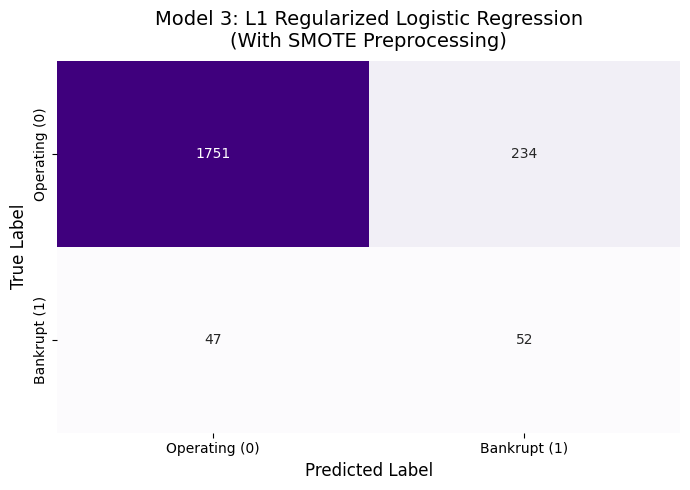

In [8]:
cm_smote = confusion_matrix(y_test, y_pred_resample)

plt.figure(figsize=(7, 5))

# Plot the heatmap
sns.heatmap(cm_smote, annot=True, fmt='d', cmap='Purples', cbar=False,
            xticklabels=['Operating (0)', 'Bankrupt (1)'], 
            yticklabels=['Operating (0)', 'Bankrupt (1)'])

plt.title('Model 3: L1 Regularized Logistic Regression\n(With SMOTE Preprocessing)', fontsize=14, pad=10)
plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('True Label', fontsize=12)
plt.tight_layout()
plt.show()

In [9]:
thresholds = [0.1, 0.2, 0.3, 0.4, 0.5]

print("Threshold | Recall (Class 1) | Precision (Class 1)")
print("-" * 47)

for t in thresholds:
    preds_resample = (y_proba_resample >= t).astype(int)
    
    report_resample = classification_report(y_test, preds_resample, output_dict=True, zero_division=0)
    
    rec_resample = report_resample['1']['recall']
    prec_resample = report_resample['1']['precision']
    
    print(f"  {t:.2f}    |      {rec_resample:.2f}       |        {prec_resample:.2f}")

Threshold | Recall (Class 1) | Precision (Class 1)
-----------------------------------------------
  0.10    |      0.96       |        0.05
  0.20    |      0.90       |        0.06
  0.30    |      0.76       |        0.09
  0.40    |      0.57       |        0.15
  0.50    |      0.53       |        0.18


In [10]:
thresholds = [0.1, 0.2, 0.3, 0.4, 0.5]

print("=" * 91)
print("                  SIDE-BY-SIDE THRESHOLD COMPARISON METRICS                        ")
print("=" * 91)
print("          MODEL 2: L1 PENALTY (CHAMPION)       |         MODEL 3: L1 + SMOTE           ")
print("-" * 91)
print("Thresh | Recall (1) | Precision (1) | F1 (1)   | Thresh | Recall (1) | Precision (1) | F1 (1)")
print("-" * 91)

for t in thresholds:
    preds_l1 = (y_prob_l1 >= t).astype(int)
    rep_l1 = classification_report(y_test, preds_l1, output_dict=True, zero_division=0)
    
    preds_smote = (y_proba_resample >= t).astype(int)
    rep_smote = classification_report(y_test, preds_smote, output_dict=True, zero_division=0)
    
    print(
        f" {t:.2f}  |    {rep_l1['1']['recall']:.2f}    |     {rep_l1['1']['precision']:.2f}      |  {rep_l1['1']['f1-score']:.2f}   | "
        f" {t:.2f}  |    {rep_smote['1']['recall']:.2f}    |     {rep_smote['1']['precision']:.2f}      |  {rep_smote['1']['f1-score']:.2f}"
    )
print("=" * 91)

                  SIDE-BY-SIDE THRESHOLD COMPARISON METRICS                        
          MODEL 2: L1 PENALTY (CHAMPION)       |         MODEL 3: L1 + SMOTE           
-------------------------------------------------------------------------------------------
Thresh | Recall (1) | Precision (1) | F1 (1)   | Thresh | Recall (1) | Precision (1) | F1 (1)
-------------------------------------------------------------------------------------------
 0.10  |    0.98    |     0.05      |  0.10   |  0.10  |    0.96    |     0.05      |  0.10
 0.20  |    0.95    |     0.05      |  0.10   |  0.20  |    0.90    |     0.06      |  0.11
 0.30  |    0.86    |     0.07      |  0.14   |  0.30  |    0.76    |     0.09      |  0.16
 0.40  |    0.61    |     0.13      |  0.21   |  0.40  |    0.57    |     0.15      |  0.23
 0.50  |    0.55    |     0.18      |  0.27   |  0.50  |    0.53    |     0.18      |  0.27


## Results:
Now recall for both of the previous models we have used balanced weights to mitigate the severe class imbalance present in our dataset. This would yeild some negative and positive results when it comes to both of our models, but we can also use another technique to deal with our class imbalance. Industry standard is to use SMOTE or Randomized Under-Sampling, but considering the fact that the Randomized Under-Sampling technique deletes data from our dataset we choose to utilize SMOTE. Note we still use the logistic regression model with l-1 regularizaton penalty but we make sure to not only perform the SMOTE sampling strategy, but also balancing out our weights for the class imbalance present in our data.

Surprisingly even with further resampling techniques our models recall ability would be slightly worse than when we just accounted for the models weights. From a recall of 55% to 53% we would lose about two correct predictions, since out of 99 companies truly labeled bankrupt we would predict only 52 of them. When we would be predicting 54/99 in our model without SMOTE. But taking a look at the precision it would seem that it remained the same at 18%. For the SMOTE model it would mean that we have labeled 289 companies as bankrupt, only 52 of them would be correctly labeled, while it would be 54/300 for our previous model. So our SMOTE model is predicting far less false positives and at the same time it has preserved its precision, which means we are technically subjecting fewer healthy companies to unnecessary audits. However, if we recall the core financial problem driving this entire project, our primary goal is to minimize catastrophic asset write-offs caused by False Negatives. Because missing a bankruptcy is vastly more expensive than raising a false alarm, a drop in Recall—even if it is only a couple of companies—is a step in the wrong direction for a risk-averse financial institution.

We also observe the effect of changing the thresholds of our SMOTE model to see if there is a point where we lose accuracy with our recall and precision. At the 40% threshold we seem to gain some of our recall score aswell as drop our recall from 18% to 15%. Comparing it with our other model it seems like the l-1 penalty model would remain the champion as it provides a far more structurally stable balance without forcing us to accept such a sharp decay in predictive certainty. Looking at our confusion matrix we would see that our SMOTE model has two more false-negatives than our regular l-1 penalty model. We go from 45 false-negatives to 47, but our false positives decrease from 245 to 234. The confusion matrix would prove our earlier statement of how SMOTE is predicting less false positives.

When we drop the threshold to 40%, the model naturally shifts to a more risk-averse stance. By requiring less mathematical certainty to flag a company as distressed, it successfully casts a wider net and captures more bankrupt firms, raising our Recall score. However, this increased sensitivity comes at a steep cost to our Precision, which plummets from 18% down to 15%.

In a real-world banking or investment environment, pushing our precision down to 15% means we are generating an even heavier wave of false alarms, forcing credit analysts to waste time auditing completely healthy companies. While we are willing to accept some false positives to protect our capital, the L1-regularized model (Model 2) achieves its 55% recall while keeping precision locked at a much cleaner 18%. Because the L1 model relies on algorithmic feature selection rather than artificial data generation and aggressive threshold manipulation, it remains the most mathematically sound and operationally efficient framework for our dataset.

## Definitions:
- Precision: Calculated as $\frac{TP}{TP+FP}$ (True Positives divided by True Positives + False Positives). It tells you how exact your model is when it predicts a positive result. (i.e. When our model flags a company as a bankrupcy risk, how often is it right? )
  
- Recall: Calculated as $\frac{TP}{TP+FN}$ (True Positives divided by True Positives + False Negatives). It tells you how capable the model is at finding all real positive cases. (i.e. Out of all the companies that actually went bankrupt, how many did our model successfully catch?)

- F1 Score: Calculated as $2 \times \frac{\text{Precision} \times \text{Recall}}{\text{Precision} + \text{Recall}}$. It uses the harmonic mean to give an equal balance between precision and recall.